> 🔑 **SOLUTION EDITION.** This copy contains worked answers to every exercise. Try the student notebook first - you learn by struggling a little!

In [1]:
# (Solution edition only) make the course helper module importable from this folder
import sys; sys.path.insert(0, '../notebooks')

# 🛍️ Project 1: Customer Segmentation
### *Duka Bora Supermarkets needs to stop sending the same SMS to everyone.*

**⏱ about 3 hours · Uses:** K-Means, hierarchical clustering, PCA, cluster evaluation & profiling (Lessons 1, 2, 4, 6)

---

## 📨 The brief

> **From:** Njeri Kamau, Marketing Director, Duka Bora Supermarkets
> **To:** You, the data scientist
> **Subject:** Customer segments: by Friday?
>
> *We have 800 customers in our loyalty programme and a budget for **three or four targeted campaigns** this quarter. Right now every customer gets the same weekly SMS and our unsubscribe rate is climbing. Can you tell me **what kinds of customers we have, how big each group is, how much each is worth to us, and what I should do about each?***
> *I'm not a technical person. I want names, numbers, and actions.; Njeri*

## 🎯 What you'll deliver
1. A **clean, scaled** feature matrix with documented choices.
2. A **justified number of segments**, backed by *four* kinds of evidence.
3. **Named segments** with profiles.
4. A **value analysis**: how much revenue does each segment generate?
5. A **one-page memo** for Njeri.

## 🗺️ Milestones

| # | Milestone | Skills |
|---|---|---|
| 1 | Data audit | pandas, skewness, missing data |
| 2 | Prepare features | imputation, log-transform, scaling |
| 3 | Choose the number of segments | silhouette, CH, DB, stability |
| 4 | Fit the final model & cross-check | K-Means vs Ward |
| 5 | Profile & name | relative heatmap |
| 6 | Value analysis | groupby, Pareto |
| 7 | Visualise | PCA |
| 8 | The memo | communication |

## 📏 Grading rubric (100 points)

| Criterion | Points |
|---|---|
| Data audit and preparation are correct and **explained** | 15 |
| Choice of *k* is supported by ≥ 3 kinds of evidence | 20 |
| Cross-check with a second algorithm | 10 |
| Segments are **named** sensibly from the profile | 15 |
| Value analysis is correct | 10 |
| Visualisation is clear and labelled | 10 |
| Memo: names, sizes, actions; non-technical; honest about caveats | 20 |

> 💡 **How to work:** read each milestone, try it *without* hints, open one hint at a time if stuck, run the ✔ self-check. Solutions are in `solutions/07_project1_customer_segmentation_SOLUTIONS.ipynb`: resist peeking until you've finished!

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import skew
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from course_utils import set_style, load, check, profile_clusters, PALETTE
set_style()
RANDOM_STATE = 42

customers = load("retail_customers")
customers.head()

,customer_id,age,gender,annual_income_kes_k,recency_days,orders_per_year,avg_basket_kes,discount_share,prefers_online,annual_spend_kes,spending_score
0,C0104,47,F,1475.0,13,45,4300,0.16,1,193500,92
1,C0632,33,M,685.0,32,8,1160,0.57,0,9280,28
2,C0544,60,F,2619.0,63,10,5411,0.08,0,54110,60
3,C0287,26,F,601.0,29,28,1089,0.76,1,30492,46
4,C0306,22,M,566.0,25,35,2553,0.32,1,89355,75


### 📖 Data dictionary: `retail_customers.csv`

| Column | Meaning |
|---|---|
| `customer_id` | Unique id (**not** a feature!) |
| `age`, `gender` | Demographics |
| `annual_income_kes_k` | Estimated annual income, thousands of KES (some missing) |
| `recency_days` | Days since last purchase |
| `orders_per_year` | Number of orders in the past year |
| `avg_basket_kes` | Average basket value (KES) |
| `discount_share` | Share of purchases made on promotion (0–1) |
| `prefers_online` | 1 if mostly buys online |
| `annual_spend_kes` | orders × basket |
| `spending_score` | A 1–100 score the supermarket already computes **from spend and recency**. *(Think: should this be a clustering feature? Hint: it's derived from other columns.)* |

## Milestone 1 · Data audit 🔍

*A professional never models data they haven't looked at.*

### 🧩 Milestone 1: Audit the data
**Difficulty:** ⭐  |  **Time:** ~10 min

Create:
- `n_missing_income`: number of missing values in `annual_income_kes_k`
- `n_dup_ids`: number of **duplicated** `customer_id`s
- `skew_spend`: the **skewness** of `annual_spend_kes` (use `scipy.stats.skew`)
- `skew_age`: skewness of `age`

Then answer in a comment: *which column(s) will need a log transform?*

<details><summary>💡 Hint 1</summary>

`customers['annual_income_kes_k'].isna().sum()`

</details>
<details><summary>💡 Hint 2</summary>

`customers['customer_id'].duplicated().sum()`

</details>
<details><summary>💡 Hint 3</summary>

`skew(customers['annual_spend_kes'])`. Rule of thumb: |skew| > 1 is strongly skewed, so use `np.log1p`.

</details>

In [3]:
n_missing_income = int(customers["annual_income_kes_k"].isna().sum())
n_dup_ids = int(customers["customer_id"].duplicated().sum())
skew_spend = skew(customers["annual_spend_kes"])
skew_age = skew(customers["age"])
print(n_missing_income, n_dup_ids, round(skew_spend, 2), round(skew_age, 2))
# annual_spend_kes is strongly right-skewed (a few huge spenders) -> log1p it. Age is roughly symmetric.

12 0 1.82 0.23


In [4]:
# ✔ Self-check (run me after you've written your answer)
check('12 customers have no income', lambda: n_missing_income == 12)
check('no duplicated ids', lambda: n_dup_ids == 0)
check('spend is strongly skewed (> 1)', lambda: skew_spend > 1)
check('age is not (|skew| < 0.5)', lambda: abs(skew_age) < 0.5)

✅ 12 customers have no income
✅ no duplicated ids
✅ spend is strongly skewed (> 1)
✅ age is not (|skew| < 0.5)


## Milestone 2 · Prepare the features 🧼

### 🧩 Milestone 2: Build the feature matrix
**Difficulty:** ⭐⭐  |  **Time:** ~15 min

Create `X_proj`, a NumPy array of **scaled** features, from a list `feature_list` of **5–8 columns** you choose.

Requirements:
- Choose features that describe **behaviour and value**: the classic **RFM** trio is **R**ecency (`recency_days`), **F**requency (`orders_per_year`), **M**onetary (`annual_spend_kes`); add others you think useful.
- **Do not** include `customer_id`, and think about whether `spending_score` should be there (it's derived from other columns).
- **Impute** missing values (median).
- **Log-transform** (`np.log1p`) the skewed columns you found in Milestone 1.
- **Standardise** with `StandardScaler`.

Keep a DataFrame `X_df` (pre-scaling, after imputing/transforming) too: you'll need it to profile later.

<details><summary>💡 Hint 1</summary>

`feature_list = ['recency_days', 'orders_per_year', 'annual_spend_kes', 'age', 'annual_income_kes_k', 'discount_share', 'prefers_online']` is a sound start.

</details>
<details><summary>💡 Hint 2</summary>

`X_df = customers[feature_list].copy(); X_df = X_df.fillna(X_df.median()); X_df['annual_spend_kes'] = np.log1p(X_df['annual_spend_kes'])`

</details>
<details><summary>💡 Hint 3</summary>

`X_proj = StandardScaler().fit_transform(X_df)`

</details>

In [5]:
feature_list = ["recency_days", "orders_per_year", "annual_spend_kes", "age", "annual_income_kes_k", "discount_share", "prefers_online"]
X_df = customers[feature_list].copy()
X_df = X_df.fillna(X_df.median())
X_df["annual_spend_kes"] = np.log1p(X_df["annual_spend_kes"])
X_proj = StandardScaler().fit_transform(X_df)
print(X_proj.shape)

(800, 7)


In [6]:
# ✔ Self-check (run me after you've written your answer)
check('5 to 8 features', lambda: 5 <= len(feature_list) <= 8)
check('customer_id is not a feature', lambda: 'customer_id' not in feature_list)
check('one row per customer', lambda: X_proj.shape[0] == 800)
check('no missing values left', lambda: not np.isnan(X_proj).any())
check('every column has mean 0 and std 1', lambda: np.allclose(X_proj.mean(axis=0), 0, atol=1e-8) and np.allclose(X_proj.std(axis=0), 1))

✅ 5 to 8 features
✅ customer_id is not a feature
✅ one row per customer
✅ no missing values left
✅ every column has mean 0 and std 1


## Milestone 3 · How many segments? 🔢

The marketing budget allows 3–4 campaigns, but let the data speak, then reconcile with the business.

### 🧩 Milestone 3: Gather the evidence for k
**Difficulty:** ⭐⭐⭐  |  **Time:** ~25 min

Build a DataFrame `eval_table` indexed by `k = 2…9` with four columns:
`silhouette`, `davies_bouldin`, `calinski_harabasz`, and `stability` (average ARI of K-Means models fitted on two 80% subsamples, each labelling **all** rows; 6 pairs is enough).

Then set `chosen_k` to an integer between **4 and 8** and write your justification in a comment: *which evidence did you weigh, and why?*

*(You wrote a stability function in Lesson 6; adapt it.)*

<details><summary>💡 Hint 1</summary>

Loop over `k`; for each fit `KMeans(k, n_init=10, random_state=42)` and compute the three scores on `X_proj`.

</details>
<details><summary>💡 Hint 2</summary>

Stability: draw `a = rng.choice(n, int(0.8*n), replace=False)` twice, fit on each, `predict(X_proj)` for all, `adjusted_rand_score(...)`.

</details>
<details><summary>💡 Hint 3</summary>

Don't just pick the silhouette maximum. Look for a k where **CH is high, DB is low-ish, stability is high**, and where the business can use the number of segments.

</details>

In [7]:
def stability(X, k, n_pairs=6, frac=0.8, seed=0):
    rng = np.random.default_rng(seed); n = len(X); out = []
    for _ in range(n_pairs):
        a = rng.choice(n, int(frac * n), replace=False); b = rng.choice(n, int(frac * n), replace=False)
        ma = KMeans(k, n_init=5, random_state=int(rng.integers(10**6))).fit(X[a])
        mb = KMeans(k, n_init=5, random_state=int(rng.integers(10**6))).fit(X[b])
        out.append(adjusted_rand_score(ma.predict(X), mb.predict(X)))
    return float(np.mean(out))

rows = []
for k in range(2, 10):
    lab = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_proj)
    rows.append(dict(k=k, silhouette=silhouette_score(X_proj, lab), davies_bouldin=davies_bouldin_score(X_proj, lab),
                     calinski_harabasz=calinski_harabasz_score(X_proj, lab), stability=stability(X_proj, k)))
eval_table = pd.DataFrame(rows).set_index("k")
display(eval_table.round(3))

# Justification: evidence is mixed, as usual. Stability is strong at k=6-7 and Calinski-Harabasz is highest around 6-7.
# Six segments are few enough for the marketing team to manage, and each is large enough to matter. -> k = 6.
chosen_k = 6

,silhouette,davies_bouldin,calinski_harabasz,stability
k,,,,
2,0.295,1.481,333.672,0.987
3,0.344,1.164,387.494,0.996
4,0.338,1.077,370.401,0.760
5,0.369,1.013,399.714,0.816
6,0.397,0.967,443.642,0.950
7,0.403,0.950,431.224,0.913
8,0.409,0.907,418.791,0.942
9,0.411,0.946,408.145,0.888


In [8]:
# ✔ Self-check (run me after you've written your answer)
check('table covers k = 2..9', lambda: list(eval_table.index) == list(range(2, 10)))
check('all four metric columns exist', lambda: {'silhouette', 'davies_bouldin', 'calinski_harabasz', 'stability'} <= set(eval_table.columns))
check('stability values are valid ARIs', lambda: eval_table['stability'].between(-0.1, 1.0001).all())
check('chosen_k is between 4 and 8', lambda: 4 <= chosen_k <= 8)

✅ table covers k = 2..9
✅ all four metric columns exist
✅ stability values are valid ARIs
✅ chosen_k is between 4 and 8


## Milestone 4 · Fit the final model and cross-check it 🔁

If *two different algorithms* find similar groups, that's strong evidence the structure is real.

### 🧩 Milestone 4: K-Means vs Ward
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

1. Fit `KMeans(chosen_k, n_init=10, random_state=42)` on `X_proj` → `labels` (NumPy array of cluster ids).
2. Fit `AgglomerativeClustering(n_clusters=chosen_k, linkage="ward")` → `ward_labels`.
3. `ari_km_ward` = the ARI between them.
4. `smallest_share` = the share (0–1) of customers in the **smallest** K-Means cluster.

<details><summary>💡 Hint 1</summary>

`labels = KMeans(chosen_k, n_init=10, random_state=42).fit_predict(X_proj)`

</details>
<details><summary>💡 Hint 2</summary>

`ward_labels = AgglomerativeClustering(n_clusters=chosen_k, linkage='ward').fit_predict(X_proj)`

</details>
<details><summary>💡 Hint 3</summary>

`smallest_share = np.bincount(labels).min() / len(labels)`

</details>

In [9]:
labels = KMeans(chosen_k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_proj)
ward_labels = AgglomerativeClustering(n_clusters=chosen_k, linkage="ward").fit_predict(X_proj)
ari_km_ward = adjusted_rand_score(labels, ward_labels)
smallest_share = np.bincount(labels).min() / len(labels)
print(round(ari_km_ward, 3), round(smallest_share, 3))

0.922 0.094


In [10]:
# ✔ Self-check (run me after you've written your answer)
check('one label per customer', lambda: len(labels) == 800)
check('K-Means and Ward agree (ARI > 0.5)', lambda: ari_km_ward > 0.5)
check('no tiny junk segment (smallest > 3%)', lambda: smallest_share > 0.03)

✅ one label per customer
✅ K-Means and Ward agree (ARI > 0.5)
✅ no tiny junk segment (smallest > 3%)


## Milestone 5 · Profile and name the segments 🏷️

### 🧩 Milestone 5: From numbers to personas
**Difficulty:** ⭐⭐  |  **Time:** ~20 min

1. Build `cust` = `customers` with median-filled numeric NaNs and a `cluster` column from `labels`.
2. `profile` = `profile_clusters(cust, labels, cols)` using the **original** (un-logged) columns:
   `["age", "annual_income_kes_k", "recency_days", "orders_per_year", "avg_basket_kes", "discount_share", "prefers_online", "annual_spend_kes"]`
3. Draw the **relative heatmap**: `(profile[cols] − cust[cols].mean()) / cust[cols].std()`.
4. Create `segment_names`: a **dict** `{cluster_id: "Your Name"}` giving every cluster a unique, descriptive name.

<details><summary>💡 Hint 1</summary>

Look for each cluster's **two or three strongest** red/blue cells and name the segment after them: *'Lapsed customers'*, *'Young online bargain-hunters'*.

</details>
<details><summary>💡 Hint 2</summary>

Typical personas in retail: loyal big spenders · bargain hunters · young/digital · wealthy occasional · frugal savers · lapsed.

</details>
<details><summary>💡 Hint 3</summary>

Your cluster ids may differ from your classmates'. That's fine; names must match **your** heatmap.

</details>

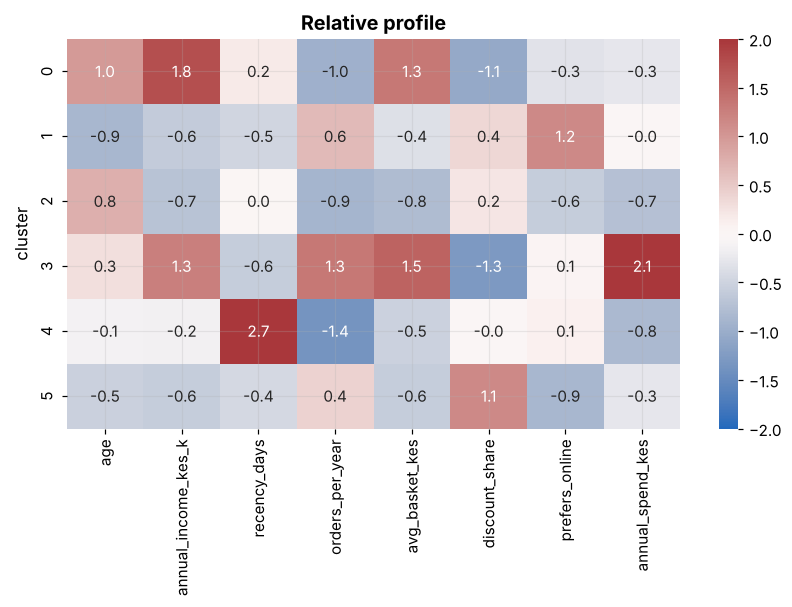

,size,share_%,age,annual_income_kes_k,recency_days,orders_per_year,avg_basket_kes,discount_share,prefers_online,annual_spend_kes
cluster,,,,,,,,,,
0,102,12.8,49.90,2101.30,70.78,8.76,3864.82,0.16,0.27,34202.99
1,202,25.2,27.77,560.46,21.09,29.78,1604.58,0.47,1.00,48302.11
2,164,20.5,47.40,491.00,59.19,9.74,1002.81,0.44,0.14,9464.57
3,120,15.0,41.59,1775.34,12.81,38.66,4152.23,0.11,0.46,159725.80
4,75,9.4,36.57,855.02,264.63,3.65,1372.92,0.39,0.48,5015.36
5,137,17.1,31.62,572.86,23.97,26.72,1293.88,0.64,0.00,34863.16


{0: 'Wealthy occasional shoppers', 1: 'Young online shoppers', 2: 'Frugal / low-activity shoppers', 3: 'Loyal big spenders', 4: 'Lapsed customers', 5: 'Bargain hunters'}


In [11]:
prof_cols = ["age", "annual_income_kes_k", "recency_days", "orders_per_year", "avg_basket_kes", "discount_share", "prefers_online", "annual_spend_kes"]
cust = customers.fillna(customers.median(numeric_only=True)).copy()
cust["cluster"] = labels
profile = profile_clusters(cust, labels, prof_cols)
relative = (profile[prof_cols] - cust[prof_cols].mean()) / cust[prof_cols].std()
plt.figure(figsize=(9, 4.6)); sns.heatmap(relative, annot=True, fmt=".1f", cmap="vlag", center=0, vmin=-2, vmax=2); plt.title("Relative profile"); plt.show()
display(profile)

# Automatic first-draft names from the dominant traits (edit these by eye after inspecting the heatmap!)
def draft_name(r):
    if r["recency_days"] > 1.5: return "Lapsed customers"
    if r["annual_spend_kes"] > 1.0 and r["orders_per_year"] > 0.8: return "Loyal big spenders"
    if r["annual_income_kes_k"] > 1.0 and r["orders_per_year"] < 0: return "Wealthy occasional shoppers"
    if r["discount_share"] > 0.8 and r["orders_per_year"] > 0: return "Bargain hunters"
    if r["age"] < -0.7 and r["prefers_online"] > 0.5: return "Young online shoppers"
    return "Frugal / low-activity shoppers"
segment_names = {c: draft_name(relative.loc[c]) for c in relative.index}
# make sure names are unique even if two clusters share a trait
seen = {}
for c, n in segment_names.items():
    seen[n] = seen.get(n, 0) + 1
    if seen[n] > 1: segment_names[c] = f"{n} (B)"
print(segment_names)

In [12]:
# ✔ Self-check (run me after you've written your answer)
check('profile has one row per cluster', lambda: len(profile) == chosen_k)
check('every cluster has a name', lambda: set(segment_names) == set(labels))
check('names are unique, non-empty strings', lambda: len(set(segment_names.values())) == chosen_k and all(isinstance(v, str) and len(v) > 3 for v in segment_names.values()))

✅ profile has one row per cluster
✅ every cluster has a name
✅ names are unique, non-empty strings


## Milestone 6 · What is each segment worth? 💰

### 🧩 Milestone 6: Revenue by segment
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

Using `cust` and `segment_names`:

1. `cust["segment"]` = the segment name of each customer.
2. `seg_revenue_share` = a Series: each segment's **share of total `annual_spend_kes`** (sums to 1), indexed by segment name.
3. `top_segment` = the name of the segment generating the most revenue.
4. `pareto_top20` = the share of total spend generated by the **top 20% of customers** (by `annual_spend_kes`), regardless of segment.

<details><summary>💡 Hint 1</summary>

`cust['segment'] = cust['cluster'].map(segment_names)`

</details>
<details><summary>💡 Hint 2</summary>

`cust.groupby('segment')['annual_spend_kes'].sum() / cust['annual_spend_kes'].sum()`

</details>
<details><summary>💡 Hint 3</summary>

`s = cust['annual_spend_kes'].sort_values(ascending=False); s.head(int(0.2 * len(s))).sum() / s.sum()`

</details>

In [13]:
cust["segment"] = cust["cluster"].map(segment_names)
seg_revenue_share = cust.groupby("segment")["annual_spend_kes"].sum() / cust["annual_spend_kes"].sum()
top_segment = seg_revenue_share.idxmax()
s = cust["annual_spend_kes"].sort_values(ascending=False)
pareto_top20 = s.head(int(0.2 * len(s))).sum() / s.sum()
size_share = cust["segment"].value_counts(normalize=True)
display(pd.DataFrame({"share of customers": size_share, "share of revenue": seg_revenue_share}).round(3).sort_values("share of revenue", ascending=False))
print(f"Top 20% of customers generate {pareto_top20:.0%} of revenue")

,share of customers,share of revenue
segment,,
Loyal big spenders,0.150,0.490
Young online shoppers,0.252,0.249
Bargain hunters,0.171,0.122
Wealthy occasional shoppers,0.128,0.089
Frugal / low-activity shoppers,0.205,0.040
Lapsed customers,0.094,0.010


Top 20% of customers generate 57% of revenue


In [14]:
# ✔ Self-check (run me after you've written your answer)
check('revenue shares sum to 1', lambda: abs(seg_revenue_share.sum() - 1) < 1e-9)
check('top_segment is a segment name', lambda: top_segment in segment_names.values())
check('Pareto effect: top 20% generate more than 50% of revenue', lambda: pareto_top20 > 0.5)

✅ revenue shares sum to 1
✅ top_segment is a segment name
✅ Pareto effect: top 20% generate more than 50% of revenue


## Milestone 7 · Draw the map 🗺️

### 🧩 Milestone 7: PCA picture of your segments
**Difficulty:** ⭐  |  **Time:** ~10 min

Project `X_proj` onto two principal components → `Z2` (shape 800×2), and make a scatter plot coloured by **segment name**, with axis labels showing the **% of variance** each PC explains. Store the two percentages in `pc_var` (a list of two floats).

*A good chart has: a title, labelled axes, a legend with segment names, readable colours.*

<details><summary>💡 Hint 1</summary>

`pca = PCA(2).fit(X_proj); Z2 = pca.transform(X_proj); pc_var = pca.explained_variance_ratio_.tolist()`

</details>
<details><summary>💡 Hint 2</summary>

Loop `for name in sorted(set(cust['segment'])):` and `plt.scatter(Z2[mask, 0], Z2[mask, 1], label=name)`, with `mask = (cust['segment'] == name).values`.

</details>

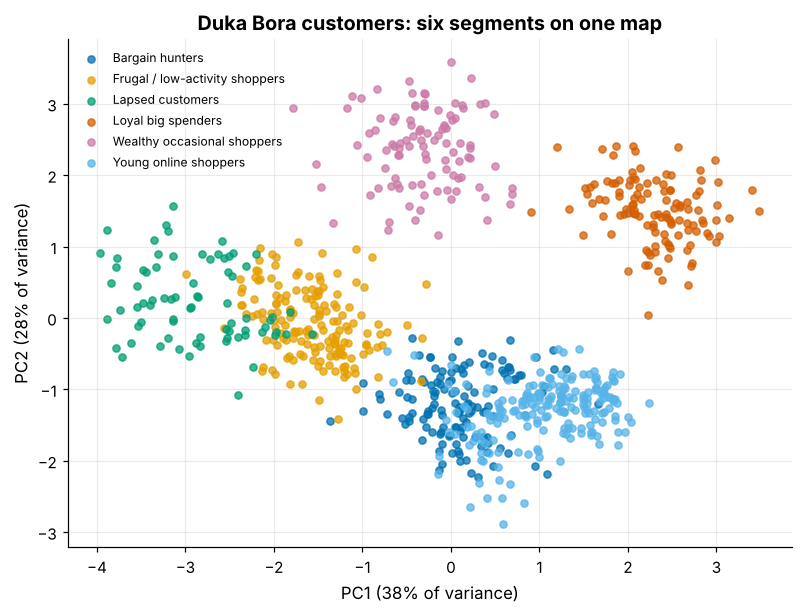

In [15]:
pca = PCA(2).fit(X_proj); Z2 = pca.transform(X_proj); pc_var = pca.explained_variance_ratio_.tolist()
fig, ax = plt.subplots(figsize=(8.5, 6))
for i, name in enumerate(sorted(set(cust["segment"]))):
    m = (cust["segment"] == name).values
    ax.scatter(Z2[m, 0], Z2[m, 1], s=22, alpha=.75, label=name, color=PALETTE[i % len(PALETTE)])
ax.set_xlabel(f"PC1 ({pc_var[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({pc_var[1]:.0%} of variance)")
ax.set_title("Duka Bora customers: six segments on one map"); ax.legend(fontsize=8, loc="best"); plt.show()

In [16]:
# ✔ Self-check (run me after you've written your answer)
check('Z2 has shape (800, 2)', lambda: Z2.shape == (800, 2))
check('pc_var has two sensible values', lambda: len(pc_var) == 2 and 0 < sum(pc_var) < 1)

✅ Z2 has shape (800, 2)
✅ pc_var has two sensible values


## Milestone 8 · The memo ✍️

This is the part that gets you promoted. Write for **Njeri**, a smart non-technical person. No jargon (no 'silhouette', 'ARI', 'PCA'): say what it *means*.

### ✍️ Memo to the Marketing Director
*(Example answer. Yours will differ in wording and possibly in numbers.)*

**To:** Njeri Kamau  **From:** Data Science  **Date:** this week

**Bottom line.** We found **six** distinct customer groups. The most valuable, **Loyal big spenders**, are only 15% of customers but generate about **49% of revenue** (overall, the top 20% of customers produce 57% of spend), so protecting them matters more than any acquisition campaign.

| Segment | Size | Who they are | Value | Recommended action |
|---|---|---|---|---|
| Loyal big spenders | 15% | Order ~38×/yr, big baskets, recent, rarely use discounts | 49% of revenue | Early access, loyalty tiers; **no blanket discounts** (they don't need them) |
| Young online shoppers | 25% | Under ~30, mostly online, steady mid-size baskets | 25% | App/SMS push, free-delivery thresholds |
| Bargain hunters | 17% | Frequent, small baskets, mostly on promotion | 12% | Targeted weekly deals; watch margin |
| Wealthy occasional shoppers | 13% | High income but only ~8 orders/yr | 9% | *Biggest upside*: raise frequency with "stock-up" offers |
| Frugal / low-activity | 20% | Low income, few small orders | 4% | Light-touch, low-cost communication |
| Lapsed customers | 9% | Haven't ordered in ~7 months | 1% | One win-back voucher; stop weekly SMS if no response |

**Top 3 recommendations**
1. **Stop the identical weekly SMS.** Send *Loyal* and *Wealthy occasional* customers premium messages; send *Bargain hunters* promotions only.
2. **Launch a win-back voucher** for the lapsed 9% and drop non-responders after 60 days (cuts unsubscribes).
3. **Target the Wealthy occasional group** with a stock-up campaign: high income, low frequency, so the largest untapped spend per customer.

**How confident are we?** Six groups appeared consistently across different random samples and were confirmed by a second, independent method, and each group is large enough to act on. *Bargain hunters* and *Young online shoppers* overlap somewhat, so treat their boundary as soft.

**Limitations / next steps.** One year of data; segments should be refreshed quarterly. Next step: run the campaigns as an A/B test, then measure uplift per segment.

## 🚀 Stretch challenges (optional, for bonus credit)

1. **RFM scoring.** Score each customer 1–5 on Recency (reverse!), Frequency, Monetary using `pd.qcut`. Combine into segments like *Champions* (R≥4, F≥4, M≥4) and *At risk* (R≤2, F≥3). How well do they match your K-Means segments? (`pd.crosstab`)
2. **Stability of names.** Re-run with `random_state=7`. Do you get the same personas? What changes?
3. **Add `gender`** (one-hot encode). Does it improve the clusters or just add noise? How do you decide?
4. **Predict new customers.** Write a function `assign_segment(new_customer_row)` using the fitted scaler and model. *(Hint: you'll need to keep your `StandardScaler` object!)*

### 🏁 Self-review checklist before you submit
- [ ] Every number in my memo can be traced to a cell in this notebook
- [ ] I explained *why* I chose k, using more than one kind of evidence
- [ ] My segment names describe what makes each group **distinctive**
- [ ] I gave **sizes** and **values**, not just descriptions
- [ ] I'd be comfortable explaining this to someone who has never heard of K-Means